# Project 1

## Imports

In [ ]:
# Imports
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

import datasets
import numpy as np
import re

from tokenizers import Tokenizer
from tabulate import tabulate
from collections import OrderedDict

from itertools import combinations
import pandas as pd

## Dataset

In [ ]:

dataset=datasets.load_dataset("gsri-18/ISEAR-dataset-complete") # we use ISEAR for the projects

In [9]:
dataset

DatasetDict({
    train: Dataset({
        features: ['emotion', 'content', 'Unnamed: 2'],
        num_rows: 7516
    })
})

In [10]:
# Small dataset statistic cell

print("Names of the splits: ", dataset.keys(), "\n"*2)
print("Number of rows: ", dataset.num_rows, "\n"*2)
print("A single Dataset: ", dataset["train"]), "\n"*2
print("Names of the splits: ", dataset["train"].features, "\n"*2)
print("Column names: ", dataset["train"].column_names, "\n"*2)
print("Rows: ", dataset["train"].num_rows, "\n"*2)
print("One example as dict: ", dataset["train"][0], "\n"*2)
print("First 5 rows as a dict of lists: ", dataset["train"][:5], "\n"*2)
print("Whole column as a list: ", dataset["train"]["content"], "\n"*2)
print("Unique emotions: ", dataset["train"].unique("emotion"), "\n"*2)


Names of the splits:  dict_keys(['train']) 


Number of rows:  {'train': 7516} 


A single Dataset:  Dataset({
    features: ['emotion', 'content', 'Unnamed: 2'],
    num_rows: 7516
})
Names of the splits:  {'emotion': Value('string'), 'content': Value('string'), 'Unnamed: 2': Value('string')} 


Column names:  ['emotion', 'content', 'Unnamed: 2'] 


Rows:  7516 


One example as dict:  {'emotion': 'joy', 'content': 'On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Unnamed: 2': None} 


First 5 rows as a dict of lists:  {'emotion': ['joy', 'fear', 'anger', 'sadness', 'disgust'], 'content': ['On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Every time I imagine that someone I love or I could contact a  \nserious illness, even death.', 'When I 

In [ ]:
class ProbabilisticModel:
    """
    A probability model is able to map input text x to a probability mass function.
    """

    def __call__(self, x: str) -> 'np.array':
        raise NotImplementedError("Concrete implementations will be discussed later")

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class SoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder: Encoder):
        self.encoder = encoder

    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x)
        raise NotImplementedError("We will get there...")

In [ ]:
# normalize and preporcess text

def normalise_text(text: str) -> str:
    # any whitespace into single blank space
    return re.sub(r"\s+", " ", text).strip()

# when inspecting the dataset there were 2 empty columns, remove them (it is also visible on HF)
if "Unnamed: 2" in dataset["train"].column_names:
    dataset = dataset.remove_columns("Unnamed: 2")

print("Before preprocessing: ", dataset["train"][0]["content"])
dataset = dataset.map(lambda ex: {"content": normalise_text(ex["content"])})

print("After preprocessing: ", dataset["train"][0]["content"])
print("Docs still containing a newline:", sum("\n" in t for t in dataset["train"]["content"]))
print("Docs with double spaces:", sum("  " in t for t in dataset["train"]["content"]))


Before preprocessing:  On days when I feel close to my partner and other friends.   
When I feel at peace with myself and also experience a close  
contact with people whom I regard greatly.
After preprocessing:  On days when I feel close to my partner and other friends. When I feel at peace with myself and also experience a close contact with people whom I regard greatly.
Docs still containing a newline: 0
Docs with double spaces: 0


In [13]:

corpus = dataset["train"]["content"]
len(corpus)
vocab_size = 1000
min_frequency = 2

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

#corpus_testing = dataset["test"]["content"]


agnews_outcome_space = part1.clslib.NamedClasses(['anger', 'disgust', 'fear', 'guilt', 'joy', 'sadness', 'shame'])
label_mapping = {name: i for i,name in enumerate(agnews_outcome_space)}
dataset = dataset.map(lambda example: {'emotion': label_mapping[example['emotion']]})


Map:   0%|          | 0/7516 [00:00<?, ? examples/s]

In [14]:
my_seeds = [0, 3, 5]
# my_seeds = [0] # to add less seeds which saves comp time

num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["content"], dataset["train"]["emotion"])),
            k=num_folds,
            seed=seed
        )
    )

In [ ]:
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [16]:
token_indicator_encoder = TokenIndicator(tokenizer)
doc_repr = token_indicator_encoder(corpus[0])

import numpy as np

def similarity(encoder, text1, text2):
    a = encoder(text1)
    b = encoder(text2)

    intersection = np.sum((a == 1) & (b == 1))
    union = np.sum((a == 1) | (b == 1))

    return intersection / union if union else 1.0

In [17]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 46 s, sys: 138 ms, total: 46.1 s
Wall time: 46.2 s


In [18]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(self.tokenizer.encode(x).ids)

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] += 1
        return vector

bow_encoder = BagOfWords(tokenizer)

In [19]:
%%time
try:

    #my_classifiers = OrderedDict()

    my_classifiers['logistic_bow-enc'] = []
    for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
        run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
        my_classifiers['logistic_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='logistic',
                save_to=run_folder,
                loglin_args={
                    'max_iter': 100
                }
            )
        )
except ImportError:
    print("You need your own implementation")


  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 46.9 s, sys: 49.8 ms, total: 46.9 s
Wall time: 47 s


In [ ]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128,
                'dropout': 0.1,
                'batch_size': 64,
                'learning_rate': 1e-3,
                'weight_decay': 1e-4,
                'num_epochs': 30,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.347 seconds
Dataloader done! Time taken: 0.051 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coal

Epoch 01 | train loss: 1.9441 | train acc: 0.1685 | val loss: 1.9319 | val acc: 0.2008
Epoch 02 | train loss: 1.9176 | train acc: 0.2332 | val loss: 1.9147 | val acc: 0.2533
Epoch 03 | train loss: 1.8920 | train acc: 0.3147 | val loss: 1.8948 | val acc: 0.3005
Epoch 04 | train loss: 1.8621 | train acc: 0.3771 | val loss: 1.8703 | val acc: 0.3351
Epoch 05 | train loss: 1.8250 | train acc: 0.4293 | val loss: 1.8396 | val acc: 0.3777
Epoch 06 | train loss: 1.7800 | train acc: 0.4677 | val loss: 1.8019 | val acc: 0.4229
Epoch 07 | train loss: 1.7287 | train acc: 0.5090 | val loss: 1.7595 | val acc: 0.4461
Epoch 08 | train loss: 1.6714 | train acc: 0.5343 | val loss: 1.7145 | val acc: 0.4634
Epoch 09 | train loss: 1.6109 | train acc: 0.5544 | val loss: 1.6687 | val acc: 0.4887
Epoch 10 | train loss: 1.5509 | train acc: 0.5669 | val loss: 1.6233 | val acc: 0.4993
Training done! Time taken: 7.787 seconds
Transforming documents...
Document transformation done! Time taken: 2.378 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

... (27 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9457 | train acc: 0.1572 | val loss: 1.9395 | val acc: 0.1803
Epoch 02 | train loss: 1.9215 | train acc: 0.2273 | val loss: 1.9225 | val acc: 0.2362
Epoch 03 | train loss: 1.8960 | train acc: 0.3028 | val loss: 1.9028 | val acc: 0.2861
Epoch 04 | train loss: 1.8660 | train acc: 0.3685 | val loss: 1.8774 | val acc: 0.3460
Epoch 05 | train loss: 1.8290 | train acc: 0.4158 | val loss: 1.8438 | val acc: 0.3965
Epoch 06 | train loss: 1.7831 | train acc: 0.4720 | val loss: 1.8034 | val acc: 0.4325
Epoch 07 | train loss: 1.7318 | train acc: 0.5007 | val loss: 1.7569 | val acc: 0.4531
Epoch 08 | train loss: 1.6709 | train acc: 0.5264 | val loss: 1.7053 | val acc: 0.4810
Epoch 09 | train loss: 1.6096 | train acc: 0.5500 | val loss: 1.6554 | val acc: 0.4904
Epoch 10 | train loss: 1.5479 | train acc: 0.5671 | val loss: 1.6050 | val acc: 0.5003
Training done! Time taken: 7.917 seconds
Transforming documents...
Document transformation done! Time taken: 2.525 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9435 | train acc: 0.1493 | val loss: 1.9346 | val acc: 0.1883
Epoch 02 | train loss: 1.9203 | train acc: 0.2335 | val loss: 1.9197 | val acc: 0.2389
Epoch 03 | train loss: 1.8948 | train acc: 0.3156 | val loss: 1.9014 | val acc: 0.2901
Epoch 04 | train loss: 1.8660 | train acc: 0.3727 | val loss: 1.8782 | val acc: 0.3287
Epoch 05 | train loss: 1.8288 | train acc: 0.4228 | val loss: 1.8489 | val acc: 0.3666
Epoch 06 | train loss: 1.7842 | train acc: 0.4741 | val loss: 1.8126 | val acc: 0.3985
Epoch 07 | train loss: 1.7320 | train acc: 0.5042 | val loss: 1.7712 | val acc: 0.4232
Epoch 08 | train loss: 1.6747 | train acc: 0.5285 | val loss: 1.7270 | val acc: 0.4451
Epoch 09 | train loss: 1.6102 | train acc: 0.5500 | val loss: 1.6808 | val acc: 0.4551
Epoch 10 | train loss: 1.5512 | train acc: 0.5674 | val loss: 1.6368 | val acc: 0.4644
Training done! Time taken: 7.914 seconds
CPU times: user 12min 48s, sys: 472 ms, total: 12min 49s
Wall time: 2min 42s


In [21]:
%%time
try:
    #from part1 import solutions
    my_classifiers['mlp_bow-enc'] = []
    for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
        run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
        my_classifiers['mlp_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='mlp',
                save_to=run_folder,
                smlp_args={
                    'hidden_dim': 128,
                    'dropout': 0.1,
                    'batch_size': 64,
                    'learning_rate': 1e-4,
                    'weight_decay': 1e-4,
                    'num_epochs': 10,
                }
            )
        )
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.815 seconds
Dataloader done! Time taken: 0.057 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9487 | train acc: 0.1489 | val loss: 1.9346 | val acc: 0.1762
Epoch 02 | train loss: 1.9200 | train acc: 0.2132 | val loss: 1.9166 | val acc: 0.2247
Epoch 03 | train loss: 1.8928 | train acc: 0.2854 | val loss: 1.8963 | val acc: 0.2812
Epoch 04 | train loss: 1.8602 | train acc: 0.3663 | val loss: 1.8705 | val acc: 0.3278
Epoch 05 | train loss: 1.8212 | train acc: 0.4182 | val loss: 1.8379 | val acc: 0.3670
Epoch 06 | train loss: 1.7763 | train acc: 0.4654 | val loss: 1.7991 | val acc: 0.3983
Epoch 07 | train loss: 1.7233 | train acc: 0.4920 | val loss: 1.7554 | val acc: 0.4322
Epoch 08 | train loss: 1.6659 | train acc: 0.5176 | val loss: 1.7097 | val acc: 0.4475
Epoch 09 | train loss: 1.6065 | train acc: 0.5321 | val loss: 1.6635 | val acc: 0.4701
Epoch 10 | train loss: 1.5484 | train acc: 0.5471 | val loss: 1.6190 | val acc: 0.4801
Training done! Time taken: 8.119 seconds
Transforming documents...
Document transformation done! Time taken: 2.656 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9392 | train acc: 0.1768 | val loss: 1.9318 | val acc: 0.1929
Epoch 02 | train loss: 1.9086 | train acc: 0.2495 | val loss: 1.9108 | val acc: 0.2535
Epoch 03 | train loss: 1.8783 | train acc: 0.3113 | val loss: 1.8854 | val acc: 0.3054
Epoch 04 | train loss: 1.8425 | train acc: 0.3805 | val loss: 1.8543 | val acc: 0.3473
Epoch 05 | train loss: 1.8011 | train acc: 0.4389 | val loss: 1.8180 | val acc: 0.3852
Epoch 06 | train loss: 1.7524 | train acc: 0.4755 | val loss: 1.7776 | val acc: 0.4232
Epoch 07 | train loss: 1.6994 | train acc: 0.4978 | val loss: 1.7345 | val acc: 0.4351
Epoch 08 | train loss: 1.6419 | train acc: 0.5247 | val loss: 1.6878 | val acc: 0.4478
Epoch 09 | train loss: 1.5863 | train acc: 0.5417 | val loss: 1.6443 | val acc: 0.4597
Epoch 10 | train loss: 1.5291 | train acc: 0.5563 | val loss: 1.6041 | val acc: 0.4637
Training done! Time taken: 8.848 seconds
Transforming documents...
Document transformation done! Time taken: 2.740 seconds
Dataloa

... (26 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9436 | train acc: 0.1573 | val loss: 1.9337 | val acc: 0.1803
Epoch 02 | train loss: 1.9181 | train acc: 0.2252 | val loss: 1.9159 | val acc: 0.2409
Epoch 03 | train loss: 1.8917 | train acc: 0.2969 | val loss: 1.8944 | val acc: 0.2908
Epoch 04 | train loss: 1.8594 | train acc: 0.3471 | val loss: 1.8672 | val acc: 0.3440
Epoch 05 | train loss: 1.8207 | train acc: 0.4111 | val loss: 1.8328 | val acc: 0.3859
Epoch 06 | train loss: 1.7732 | train acc: 0.4538 | val loss: 1.7920 | val acc: 0.4172
Epoch 07 | train loss: 1.7227 | train acc: 0.4863 | val loss: 1.7467 | val acc: 0.4424
Epoch 08 | train loss: 1.6642 | train acc: 0.5089 | val loss: 1.6992 | val acc: 0.4624
Epoch 09 | train loss: 1.6068 | train acc: 0.5300 | val loss: 1.6526 | val acc: 0.4731
Epoch 10 | train loss: 1.5495 | train acc: 0.5430 | val loss: 1.6074 | val acc: 0.4923
Training done! Time taken: 8.155 seconds
Transforming documents...
Document transformation done! Time taken: 2.435 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9471 | train acc: 0.1543 | val loss: 1.9345 | val acc: 0.1803
Epoch 02 | train loss: 1.9173 | train acc: 0.2145 | val loss: 1.9151 | val acc: 0.2315
Epoch 03 | train loss: 1.8870 | train acc: 0.2924 | val loss: 1.8928 | val acc: 0.2901
Epoch 04 | train loss: 1.8517 | train acc: 0.3679 | val loss: 1.8653 | val acc: 0.3420
Epoch 05 | train loss: 1.8094 | train acc: 0.4247 | val loss: 1.8328 | val acc: 0.3713
Epoch 06 | train loss: 1.7613 | train acc: 0.4708 | val loss: 1.7941 | val acc: 0.3925
Epoch 07 | train loss: 1.7065 | train acc: 0.4936 | val loss: 1.7533 | val acc: 0.4112
Epoch 08 | train loss: 1.6479 | train acc: 0.5257 | val loss: 1.7118 | val acc: 0.4271
Epoch 09 | train loss: 1.5922 | train acc: 0.5450 | val loss: 1.6698 | val acc: 0.4444
Epoch 10 | train loss: 1.5316 | train acc: 0.5644 | val loss: 1.6317 | val acc: 0.4531
Training done! Time taken: 7.543 seconds
CPU times: user 12min 36s, sys: 367 ms, total: 12min 36s
Wall time: 2min 39s


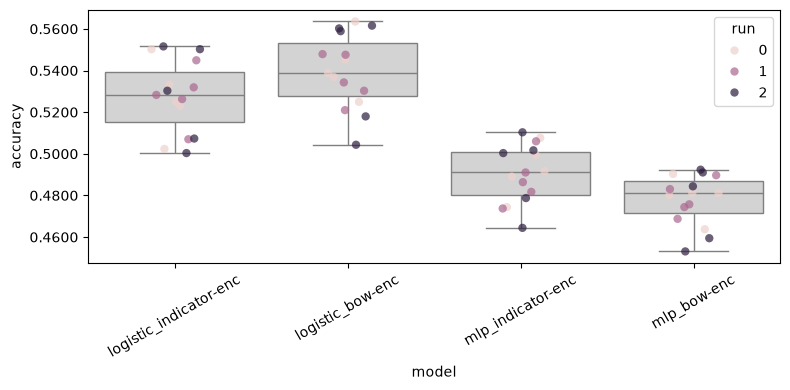

In [22]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

# Additionals


# TF IDF

Implementation is based on https://medium.com/bitgrit-data-science-publication/tf-idf-from-scratch-in-python-ea587d003e9e

In [30]:
def tf(word_counts: dict, document: list) -> dict:
    """Calculate term frequency of each word in a document."""
    tf_dict = {}
    corpus_count = max(len(document), 1)   # guard against empty documents

    for word, count in word_counts.items():
        tf_dict[word] = count / float(corpus_count)

    return tf_dict


def idf(documents: list, vocab) -> dict:
    """For each term, the (smoothed) inverse of the number of documents it appears in."""
    N = len(documents)
    idf_dict = dict.fromkeys(vocab, 0)

    for doc in documents:
        for word in set(doc):          # count each term once per document
            idf_dict[word] += 1

    for word, df in idf_dict.items():
        idf_dict[word] = np.log10((N + 1.0) / (df + 1.0))

    return idf_dict


def tfidf(doc_elements: dict, idfs: dict) -> dict:
    """TF * IDF per word given a single document."""
    tfidf_dict = {}

    for word, val in doc_elements.items():
        tfidf_dict[word] = val * idfs[word]

    return tfidf_dict


class TfIdf(Encoder):

    def __init__(self, tokenizer: Tokenizer, fit_corpus: list):
        self.tokenizer = tokenizer
        self.vocab = range(tokenizer.get_vocab_size())   # token ids are our "words"
        self.idfs = idf([tokenizer.encode(text).ids for text in fit_corpus], self.vocab)

    def __len__(self) -> int:
        return len(self.vocab)

    def __call__(self, x: str) -> 'np.array':
        document = self.tokenizer.encode(x).ids

        word_counts = dict.fromkeys(self.vocab, 0)
        for word in document:
            word_counts[word] += 1

        scores = tfidf(tf(word_counts, document), self.idfs)
        vector = np.array([scores[word] for word in self.vocab])

        norm = np.linalg.norm(vector)                    # L2-normalise (see note above)
        return vector / norm if norm > 0 else vector


tfidf_encoder = TfIdf(tokenizer, corpus)

vec = tfidf_encoder(corpus[0])
print(vec.shape, "non-zero entries:", np.count_nonzero(vec))
top = np.argsort(vec)[::-1][:5]
print([(tokenizer.id_to_token(int(i)), round(float(vec[i]), 3)) for i in top])


(1000,) non-zero entries: 34
[('▁close', 0.321), ('▁feel', 0.307), ('▁pe', 0.263), ('ace', 0.216), ('ner', 0.211)]


In [31]:
%%time
my_classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    my_classifiers['logistic_tfidf-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=tfidf_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100},
        )
    )


  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python

CPU times: user 49.1 s, sys: 64 ms, total: 49.2 s
Wall time: 49.2 s


# Bayesian estimation and ROPE

In [24]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator-enc')

array([[0.53324468, 0.50232868, 0.5249501 , 0.52295409, 0.55023287],
       [0.53191489, 0.52628077, 0.54491018, 0.52827678, 0.50698603],
       [0.50731383, 0.55023287, 0.53027279, 0.55156354, 0.50033267]])

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=1.0000 P(Tie)=0.0000 P(B wins)=0.0000 Effect Size=-10.12


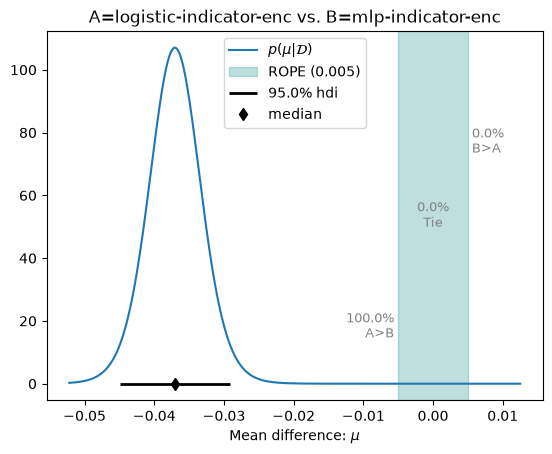

In [25]:
posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc", "mlp-indicator-enc"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)

In [ ]:


ROPE = 0.005 

def compare_all_pairs(classifiers, rope_size=ROPE, runs=1, plot=False):
    rows = []
    for name_a, name_b in combinations(classifiers.keys(), 2):
        posterior = part1.analysis.BenavoliCorrelatedT(
            get_all_measurements_for(classifiers, name_a).flatten(),
            get_all_measurements_for(classifiers, name_b).flatten(),
            runs=runs,
            names=[name_a, name_b],
        )
        p_a, p_tie, p_b = posterior.probs(rope_size)
        rows.append({
            "A": name_a,
            "B": name_b,
            "mean diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a,
            "P(tie / in ROPE)": p_tie,
            "P(B wins)": p_b,
            "effect size": posterior.effect_size,
        })
        if plot:
            posterior.plot(rope_size)
    return pd.DataFrame(rows)

results_df = compare_all_pairs(my_classifiers, rope_size=ROPE, runs=len(my_seeds))
results_df.style.format({
    "mean diff (B-A)": "{:+.4f}",
    "P(A wins)": "{:.3f}",
    "P(tie / in ROPE)": "{:.3f}",
    "P(B wins)": "{:.3f}",
    "effect size": "{:.2f}",
})


,A,B,mean diff (B-A),P(A wins),P(tie / in ROPE),P(B wins),effect size
0,logistic_indicator-enc,logistic_bow-enc,+0.0121,0.001,0.058,0.941,2.85
1,logistic_indicator-enc,mlp_indicator-enc,-0.0370,1.000,0.000,0.000,-6.68
2,logistic_indicator-enc,mlp_bow-enc,-0.0496,1.000,0.000,0.000,-9.98
3,logistic_bow-enc,mlp_indicator-enc,-0.0491,1.000,0.000,0.000,-14.05
4,logistic_bow-enc,mlp_bow-enc,-0.0617,1.000,0.000,0.000,-10.97
5,mlp_indicator-enc,mlp_bow-enc,-0.0125,0.895,0.100,0.004,-2.19


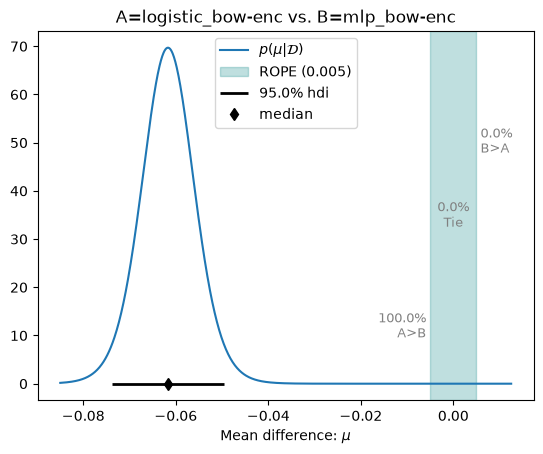

In [27]:
posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_bow-enc').flatten(),
    get_all_measurements_for(my_classifiers, 'mlp_bow-enc').flatten(),
    runs=len(my_seeds),
    names=['logistic_bow-enc', 'mlp_bow-enc'],
)
_ = posterior.plot(ROPE)
